# Quantum annealing evolution: bath relaxation and local SEAQT

An open-system model for quantum annealing: a qubit register coupled to a
fixed-temperature bath, driven by the real D-Wave QPU annealing
Hamiltonian. This notebook walks through the physics, validates it live,
and builds up from 1 qubit to 2 coupled qubits, using **two** dissipators:

1. **`bath_dissipator`** (sections 1-4) -- the whole composite system
   relaxes toward a single global Gibbs state.
2. **`local_seaqt_dissipator`** (sections 6-9) -- from Yamada, Kusaba,
   Li, von Spakovsky et al., arXiv:2404.05473v3 (eqs. 6, 7, 15); each
   qubit relaxes *locally*, coupled to the other only through their
   current reduced states.

**Physics common to both**

$$\dot\rho\big|_{\text{unitary}} = -\frac{i}{\hbar}[H(t), \rho]$$

with the D-Wave QPU Hamiltonian

$$H(s) = -\frac{A(s)}{2}\sum_i \sigma_x^{(i)} + \frac{B(s)}{2}\Big(\sum_i h_i \sigma_z^{(i)} + \sum_{i<j} J_{ij}\sigma_z^{(i)}\sigma_z^{(j)}\Big)$$

$A(s), B(s)$ read from the real QPU datasheet, $s=t/t_{\text{anneal}}\in[0,1]$.

**`bath_dissipator`** relaxes $\rho$ toward the Gibbs (canonical) state
$e^{-\beta H}/Z$ at bath inverse temperature $\beta$:

$$\dot\rho\big|_{\text{diss}} = -\frac{\beta}{2\tau}\{F(\rho,H,\beta),\rho\},
  \qquad F = (H-\langle H\rangle_\rho I) - \tfrac{1}{\beta}(S_{\mathrm{op}}-\langle S_{\mathrm{op}}\rangle_\rho I)$$

with $S_{\mathrm{op}}=-\ln\rho$. Both bracketed terms are "fluctuation
operators" with zero expectation in $\rho$ by construction, which is what
guarantees trace conservation with no extra projection step. Its 2nd-law
equivalent: the free energy $\Omega(\rho)=\langle H\rangle_\rho - S(\rho)/\beta$
decreases monotonically to its minimum at the Gibbs state.

**`local_seaqt_dissipator`** relaxes each qubit $J\in\{A,B\}$ locally:

$$\dot{\rho}\vert_{\text{diss}} = -\sum_{J = 1}^{M} \frac{1}{\tau_J}\hat{D}_J\otimes\hat{\rho}_{\bar{J}}, \qquad \hat{D}_J = \hat{\rho}_J \ln \hat{\rho}_J - \beta_R \langle f \rangle_J \hat{\rho}_J +\frac{1}{2} \beta_R \{ \hat{H}_J , \hat{\rho}_J\}$$


with $\rho_J=\mathrm{Tr}_{\bar J} (\rho)$, $H_J$ the "locally perceived" Hamiltonian
(traced over the other qubit, weighted by its current state). `Tr(D_J)=0`
exactly by construction (see section 9).

See `README.md` for the full derivation and sign/unit conventions.

In [ ]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def _find_repo_root(start: Path) -> Path:
    """Walk upward from `start` until we find THIS repo (identified by
    seaqt/local_seaqt.py, a file unique to this project) -- robust to
    whatever directory the Jupyter kernel happens to use as its cwd.
    VSCode's Jupyter extension commonly uses the workspace root rather than
    the notebook's own folder, so `os.getcwd() + "/.."` isn't reliable."""
    for candidate in [start, *start.parents]:
        if (candidate / "seaqt" / "local_seaqt.py").exists():
            return candidate
    raise RuntimeError(
        "Could not locate the SEAQT-quantum-annealing-evolution repo root "
        f"above {start} -- expected to find seaqt/local_seaqt.py in some "
        "parent directory."
    )


REPO_ROOT = _find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import seaqt as _seaqt_probe
_seaqt_probe_path = Path(_seaqt_probe.__file__).resolve()
if REPO_ROOT not in _seaqt_probe_path.parents:
    raise RuntimeError(
        f"'seaqt' resolved to {_seaqt_probe_path}, NOT this repo "
        f"({REPO_ROOT}) -- most likely a same-named 'seaqt' package from a "
        "different project, already cached in this kernel's sys.modules "
        "from an earlier import in the same session. Restart the kernel "
        "(Kernel > Restart) and re-run this notebook from the top."
    )
del _seaqt_probe, _seaqt_probe_path

from seaqt import bath_dissipator, entropy, evolve, free_energy, free_energy_operator, gibbs_state, hermitize, population_distribution
from seaqt.local_seaqt import local_seaqt_dissipator, locally_perceived_operator, reduced_state, _subsystem_dissipator
from seaqt.local_seaqt_n import local_seaqt_dissipator_n
from seaqt.operators import basis_labels, ising_hamiltonian, sigma_x, sigma_z
from seaqt.dwave import load_schedule, hamiltonian_1qubit, hamiltonian_nqubit, beta_from_kelvin

SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1265A-C_Advantage_system5_3_annealing_schedule.xlsx"
)

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=4, suppress=True)
print(f"Setup OK. seaqt loaded from: {REPO_ROOT}")


Setup OK. seaqt loaded from: c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution


## 1. Physics validation, live

Rather than just trusting the tests, compute the dissipator directly and
check the invariants it claims to satisfy: trace conservation, and that it
vanishes exactly at the Gibbs equilibrium state.

In [3]:
H_demo = 0.5 * sigma_z + 0.3 * sigma_x
beta_demo = 1.5

rho_eq = gibbs_state(H_demo, beta_demo)
D_at_eq = bath_dissipator(rho_eq, H_demo, beta_demo, tau=1.0)
print("Dissipator at the Gibbs state (should be ~0):")
print(D_at_eq)
print(f"max|D| = {np.max(np.abs(D_at_eq)):.3e}")

rho_away = np.array([[0.6, 0.15 - 0.1j], [0.15 + 0.1j, 0.4]], dtype=complex)
D_away = bath_dissipator(rho_away, H_demo, beta_demo, tau=1.0)
print(f"\nAway from equilibrium, max|D| = {np.max(np.abs(D_away)):.3e} (nonzero, as expected)")
print(f"Tr(D)   = {np.trace(D_away):.3e}  (want 0)")

Dissipator at the Gibbs state (should be ~0):
[[-0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]
max|D| = 1.938e-16

Away from equilibrium, max|D| = 4.348e-01 (nonzero, as expected)
Tr(D)   = 0.000e+00+0.000e+00j  (want 0)


## 2. One qubit -- real D-Wave schedule + bath relaxation

A simpler stepping stone before 2 qubits: single qubit, real QPU schedule,
relaxing toward a fixed-temperature bath. Note D-Wave's sign convention:
no leading minus on the $B(s)$ term, so the ground state is $|0\rangle$
for $h_1<0$.

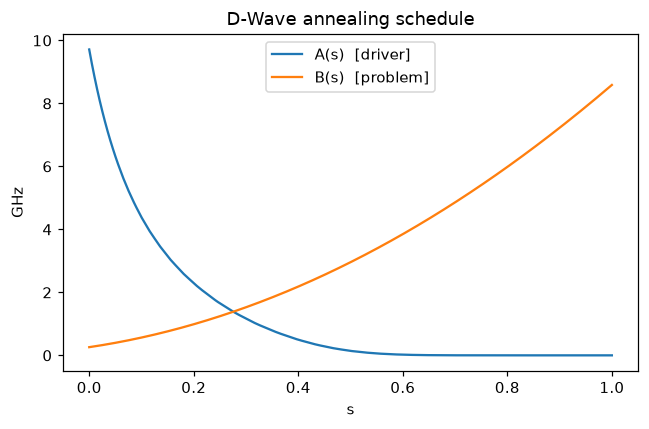

In [4]:
schedule = load_schedule(SCHEDULE_PATH)
s_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s_grid, schedule.A(s_grid), label="A(s)  [driver]")
ax.plot(s_grid, schedule.B(s_grid), label="B(s)  [problem]")
ax.set_xlabel("s"); ax.set_ylabel("GHz"); ax.legend(); ax.set_title("D-Wave annealing schedule")
fig.tight_layout(); plt.show()

beta (15 mK) = 0.5092 ns
             tau=2: final P(|0>)=0.9761, final entropy=0.1127, final Omega=-4.3096
            tau=10: final P(|0>)=0.9953, final entropy=0.0300, final Omega=-4.3115
 tau=inf (unitary): final P(|0>)=0.9997, final entropy=0.0000, final Omega=-4.2909


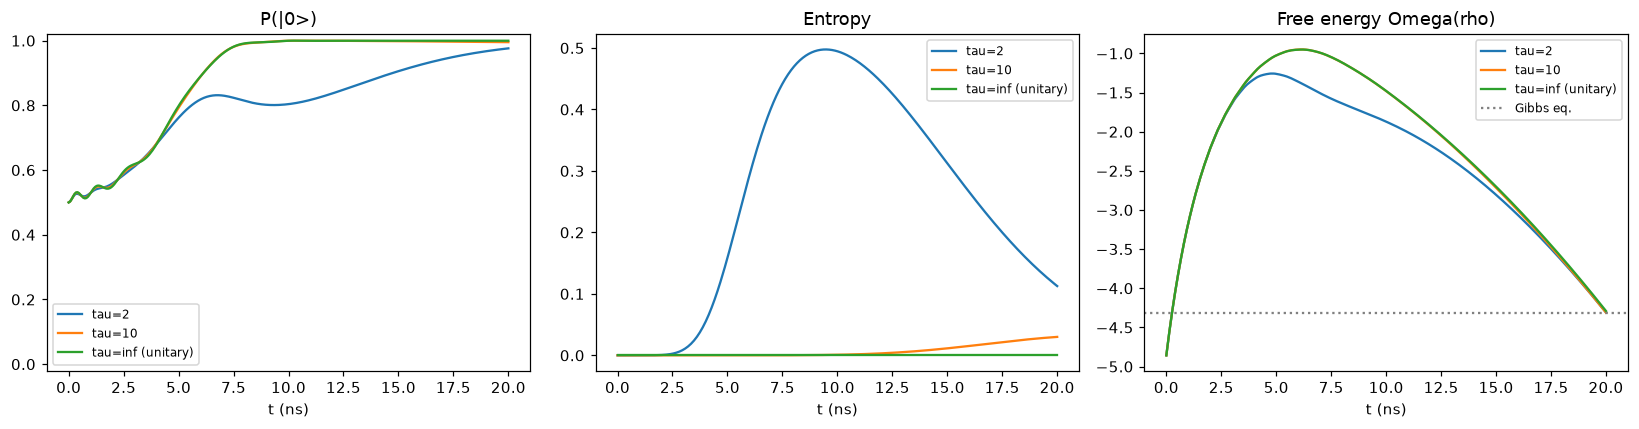

In [5]:
def run_1q_bath(H, t_anneal, tau, beta, n_points=300):
    rho0 = np.array([[0.5, 0.5], [0.5, 0.5]], dtype=complex)  # |+><+| (driver ground state)
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p0, ent, omega

t_anneal_1q = 20.0
H_1q = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_1q)
beta_bath = beta_from_kelvin(0.015)  # 15 mK
print(f"beta (15 mK) = {beta_bath:.4f} ns")

taus_1q = [2.0, 10.0, np.inf]
labels = {2.0: "tau=2", 10.0: "tau=10", np.inf: "tau=inf (unitary)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for tau in taus_1q:
    t, p0, ent, omega = run_1q_bath(H_1q, t_anneal_1q, tau, beta_bath)
    axes[0].plot(t, p0, label=labels[tau])
    axes[1].plot(t, ent, label=labels[tau])
    axes[2].plot(t, omega, label=labels[tau])
    print(f"{labels[tau]:>18}: final P(|0>)={p0[-1]:.4f}, final entropy={ent[-1]:.4f}, final Omega={omega[-1]:.4f}")
h1_final = H_1q(t_anneal_1q)
omega_eq_1q = free_energy(gibbs_state(h1_final, beta_bath), h1_final, beta_bath)
axes[2].axhline(omega_eq_1q, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title("P(|0>)"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 3. $t_{\text{anneal}} \times \tau$ sweep (1 qubit, bath, real D-Wave schedule)

Since the bath's target is the Gibbs state rather than a fixed pure state,
dissipation doesn't only compete with reaching the answer the way a
fixed-energy dissipator would -- sweep across anneal time and relaxation
rate to see where it helps or hurts.

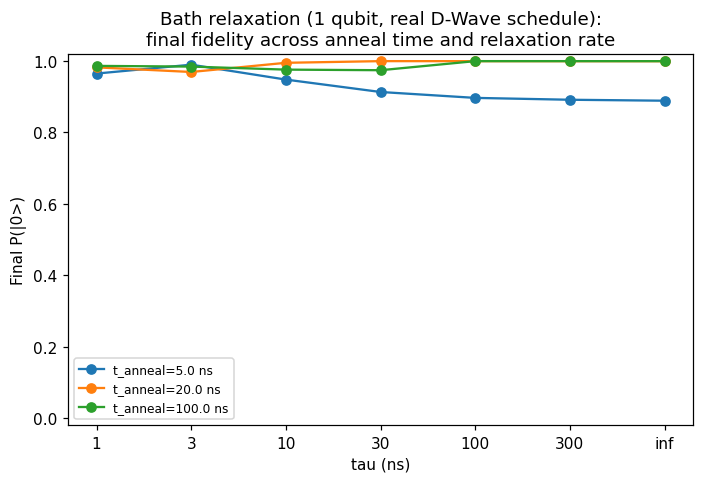

For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than
the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a
pure state and so can only compete with, never help, reaching one.


In [5]:
tau_sweep = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, np.inf]
labels_sweep = [f"{t:g}" if np.isfinite(t) else "inf" for t in tau_sweep]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for t_anneal in [5.0, 20.0, 100.0]:
    H_sweep = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal)
    finals = [run_1q_bath(H_sweep, t_anneal, tau, beta_bath, n_points=120)[1][-1] for tau in tau_sweep]
    ax.plot(labels_sweep, finals, marker="o", label=f"t_anneal={t_anneal} ns")
ax.set_xlabel("tau (ns)"); ax.set_ylabel("Final P(|0>)")
ax.set_title("Bath relaxation (1 qubit, real D-Wave schedule):\nfinal fidelity across anneal time and relaxation rate")
ax.legend(fontsize=8); ax.set_ylim(-0.02, 1.02)
fig.tight_layout(); plt.show()

print("For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than")
print("the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a")
print("pure state and so can only compete with, never help, reaching one.")

## 4. Why can a *shorter* anneal beat a longer one at the same tau? A moving target

Section 3's sweep showed something that looks backwards at first:
`t_anneal=20` can end up with a *higher* final `P(|0>)` than `t_anneal=100`
at the same `tau`. The resolution is that the unitary part and the
dissipative part of the dynamics are chasing two genuinely different
targets:

* **annealing (unitary)** pursues the *instantaneous ground state* of
  $H(t)$ -- a pure state, ideal target $P(|0\rangle)=1$;
* **`bath_dissipator`** pursues the *instantaneous Gibbs state* of that
  same $H(t)$ at the bath's temperature -- a mixed (thermal) state, whose
  $P(|0\rangle)$ rises with $s=t/t_{\text{anneal}}$ but only reaches
  $\approx 0.9875$ at $s=1$ for this schedule/temperature, never $1$,
  because the bath temperature is finite (residual thermal population in
  the excited state, however small).

"Same `tau`" is a fixed *rate* toward that moving target, not a fixed
*outcome* -- a longer anneal gives the bath strictly more absolute time to
pull the trajectory toward wherever that target currently sits, which for
most of the schedule is *below* its final value.

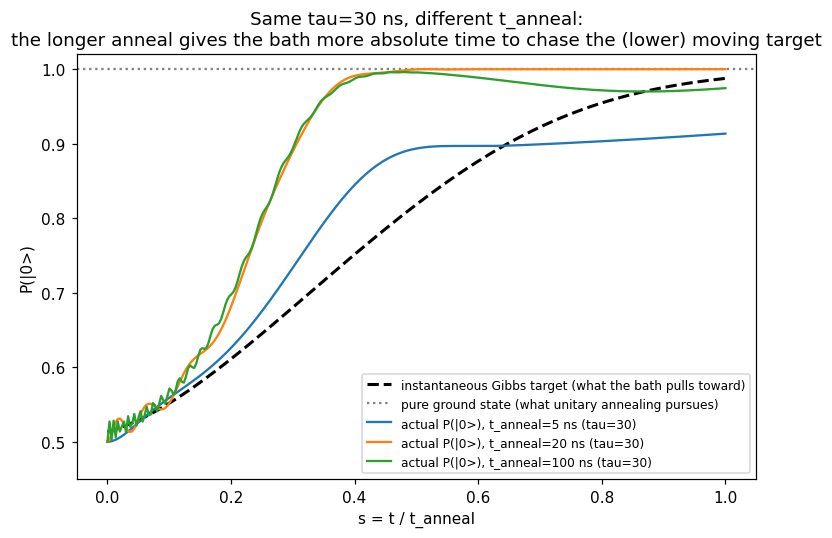

Bath's true final target at s=1: P(|0>) = 0.9875  (not 1.0 -- finite bath temperature)

    s | instant-Gibbs target |  actual, t_anneal=5 |  actual, t_anneal=20 |  actual, t_anneal=100


 0.00 |               0.5132 |              0.5000 |               0.5000 |                0.5000
 0.25 |               0.6450 |              0.6761 |               0.7979 |                0.8057
 0.50 |               0.8184 |              0.8937 |               0.9998 |                0.9956
 0.75 |               0.9401 |              0.9011 |               0.9999 |                0.9746
 0.90 |               0.9754 |              0.9080 |               0.9999 |                0.9703
 1.00 |               0.9875 |              0.9135 |               0.9999 |                0.9745


In [6]:
H_ref_s = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=1.0)  # t_anneal=1 -> t IS s directly
s_grid_target = np.linspace(0, 1, 100)
gibbs_target_curve = np.array([gibbs_state(H_ref_s(s), beta_bath)[0, 0].real for s in s_grid_target])

tau_mt = 30.0
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(s_grid_target, gibbs_target_curve, "k--", lw=2,
        label="instantaneous Gibbs target (what the bath pulls toward)")
ax.axhline(1.0, color="gray", linestyle=":",
           label="pure ground state (what unitary annealing pursues)")

for t_anneal_mt in [5.0, 20.0, 100.0]:
    H_mt = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_mt)
    t, p0, ent, omega = run_1q_bath(H_mt, t_anneal_mt, tau_mt, beta_bath, n_points=300)
    ax.plot(t / t_anneal_mt, p0, label=f"actual P(|0>), t_anneal={t_anneal_mt:g} ns (tau={tau_mt:g})")

ax.set_xlabel("s = t / t_anneal"); ax.set_ylabel("P(|0>)")
ax.set_title(f"Same tau={tau_mt:g} ns, different t_anneal:\nthe longer anneal gives the bath more absolute time to chase the (lower) moving target")
ax.legend(fontsize=8, loc="lower right"); ax.set_ylim(0.45, 1.02)
fig.tight_layout(); plt.show()

print(f"Bath's true final target at s=1: P(|0>) = {gibbs_target_curve[-1]:.4f}  (not 1.0 -- finite bath temperature)")
print()
print(f"{'s':>5} | {'instant-Gibbs target':>20} | {'actual, t_anneal=5':>19} | {'actual, t_anneal=20':>20} | {'actual, t_anneal=100':>21}")
H5 = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=5.0)
H20 = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=20.0)
H100 = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=100.0)
_, p0_5, _, _ = run_1q_bath(H5, 5.0, tau_mt, beta_bath, n_points=300)
_, p0_20, _, _ = run_1q_bath(H20, 20.0, tau_mt, beta_bath, n_points=300)
_, p0_100, _, _ = run_1q_bath(H100, 100.0, tau_mt, beta_bath, n_points=300)
for s_chk in [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]:
    idx5 = int(round(s_chk * (len(p0_5) - 1)))
    idx20 = int(round(s_chk * (len(p0_20) - 1)))
    idx100 = int(round(s_chk * (len(p0_100) - 1)))
    target_val = gibbs_state(H_ref_s(s_chk), beta_bath)[0, 0].real
    print(f"{s_chk:5.2f} | {target_val:20.4f} | {p0_5[idx5]:19.4f} | {p0_20[idx20]:20.4f} | {p0_100[idx100]:21.4f}")

Reading the plot and table together: all three trajectories race
ahead of the instantaneous Gibbs target early on (the unitary/adiabatic
part wins that phase, since the minimum gap for this problem closes
around $s\approx 0.3$-$0.5$). Past that point, `t_anneal=20` only has a
handful of nanoseconds left -- at `tau=30` that is well under one
relaxation time, not enough for the bath to noticeably pull the
"overshoot" back down before the anneal ends. `t_anneal=100` has ~5x more
absolute time in that same window -- enough for the bath to visibly drag
`P(|0>)` back down toward the still-rising-but-lower target, and it
doesn't fully recover by $s=1$.

`t_anneal=5` looks different again: it never gets far enough ahead of the
target to have an "overshoot" to lose in the first place (`0.9135` at
$s=1$, versus `0.9880`/`0.9651` for `t_anneal=100`/`20`) -- but comparing
it to its *own* unitary-only limit (below) shows `tau=30` is still net
*helping* it, not hurting, which is the opposite direction from the other
two.

This is why the effect is strongest for `tau` comparable to the
*leftover* time after the gap closes, not for very strong dissipation
(locked to the target from the start, so there is no overshoot to lose)
or very weak dissipation (negligible pull either way).

## 5. Extending to N qubits

`seaqt.operators` builds Pauli operators on any qubit of an $n$-qubit
register via Kronecker products, and assembles the (D-Wave-convention)
Ising Hamiltonian. `bath_dissipator` and `evolve` never assumed 2x2 --
they work unmodified for any Hilbert-space dimension.

In [6]:
H2 = ising_hamiltonian(2, h=[0.6, -0.4], J={(0, 1): 0.5}, A=1.0, B=0.7)
print("2-qubit Hamiltonian, shape", H2.shape, ", Hermitian:", np.allclose(H2, H2.conj().T))
print(H2.real)

rho2 = hermitize(np.eye(4, dtype=complex) / 4 + 0.05 * np.random.default_rng(0).normal(size=(4, 4)))
rho2 /= np.trace(rho2).real
D2 = bath_dissipator(rho2, H2, beta=1.0, tau=1.0)
print(f"\n2-qubit bath dissipator: Tr(D)={np.trace(D2):.2e}  (want 0)")

2-qubit Hamiltonian, shape (4, 4) , Hermitian: True
[[ 0.245 -0.5   -0.5    0.   ]
 [-0.5    0.175  0.    -0.5  ]
 [-0.5    0.    -0.525 -0.5  ]
 [ 0.    -0.5   -0.5    0.105]]

2-qubit bath dissipator: Tr(D)=-1.11e-16+0.00e+00j  (want 0)


## 6. Two qubits -- real D-Wave schedule + local SEAQT relaxation

The main result this repo is built around: two coupled qubits, the real
QPU annealing schedule, each qubit relaxing *locally* via
`local_seaqt_dissipator` (section 9 has the full derivation/validation).

The initial state is a slightly-thermalized driver state
(`gibbs_state(H(0), beta_init)`, `beta_init` large enough to be
numerically indistinguishable from the exact pure ground state) -- this
is a convention carried over from the `bath_dissipator` demos, not a
numerical necessity here: section 8 confirms `local_seaqt_dissipator`
handles pure states cleanly (including a maximally *entangled* pure
state, the genuinely analogous danger for this dissipator), and swapping
in the exact pure state changes nothing at the precision shown below. The
linear bias $h=[0.6,-0.4]$ is asymmetric simply so the problem has a
unique ground state, making $P(\text{ground})$ a meaningful quantity to
plot directly -- section 7 runs the same setup with the symmetric,
genuinely undecided $h=[0,0]$ instead. `tau_A=tau_B \ge 10` ns is used
here deliberately: section 9 shows positivity of $\rho$ can be violated
for smaller, more aggressive `tau` with this schedule.

Ground state: |10>, gap=7.7277
      tau_A=tau_B=10: final distribution P(|00>)=0.0227, P(|01>)=0.0186, P(|10>)=0.9144, P(|11>)=0.0443
      tau_A=tau_B=30: final distribution P(|00>)=0.0097, P(|01>)=0.0076, P(|10>)=0.9651, P(|11>)=0.0175
tau = inf (unitary only): final distribution P(|00>)=0.0008, P(|01>)=0.0046, P(|10>)=0.9880, P(|11>)=0.0066


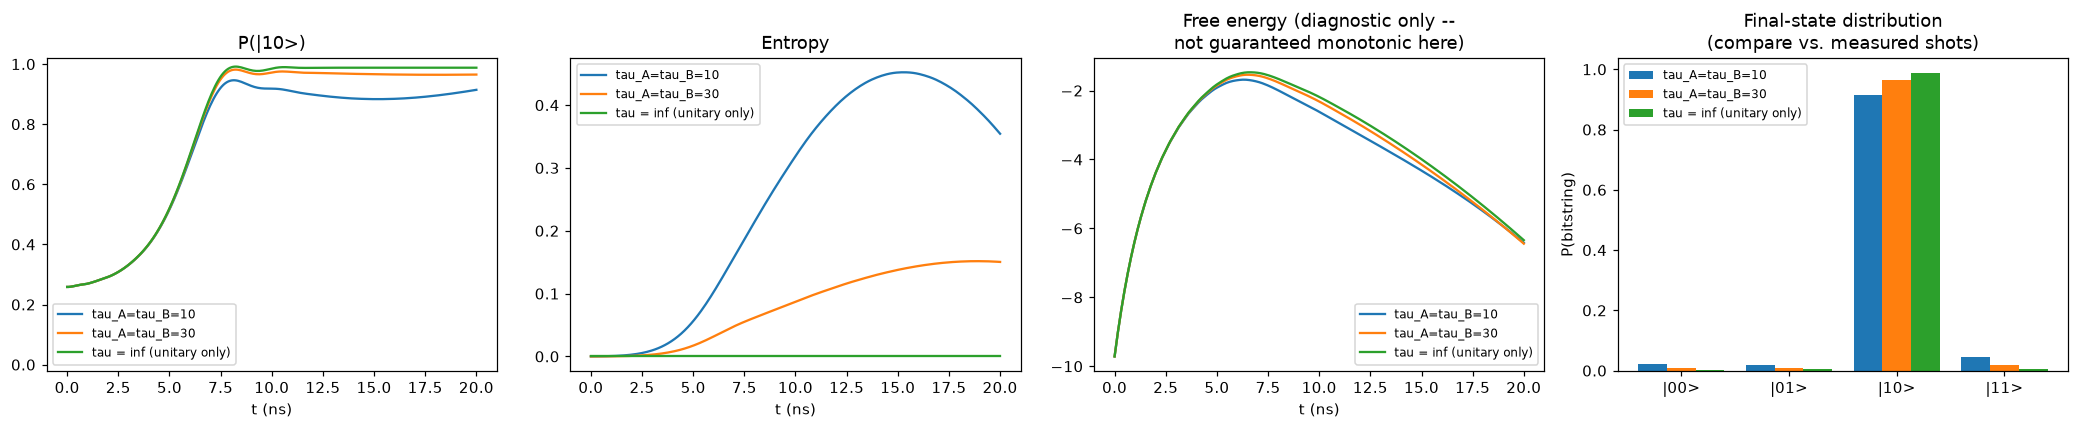

In [8]:
H_BIAS_2Q = [0.6, -0.4]
J12 = 0.5
BETA_INIT = 5.0

def run_2q_local_seaqt(H, t_anneal, tau, beta_r, n_points=250):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r, tau_a=tau, tau_b=tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta_r) for t, r in zip(res.t, res.rho)])
    final_dist = population_distribution(res.rho[-1])
    return res.t, p_ground, ent, omega, final_dist

t_anneal_2q = 20.0
H_2q = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal_2q)
h2_final = H_2q(t_anneal_2q)
w2, v2 = np.linalg.eigh(h2_final)
labels_bits_2q = basis_labels(2)
ground_idx_2q = int(np.argmax(np.abs(v2[:, 0])))
print(f"Ground state: {labels_bits_2q[ground_idx_2q]}, gap={w2[1]-w2[0]:.4f}")

taus_2q = [10.0, 30.0, np.inf]
labels_2q = {10.0: "tau_A=tau_B=10", 30.0: "tau_A=tau_B=30", np.inf: "tau = inf (unitary only)"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
final_dists_2q = {}
for tau in taus_2q:
    t, p_ground, ent, omega, final_dist = run_2q_local_seaqt(H_2q, t_anneal_2q, tau, beta_bath)
    final_dists_2q[tau] = final_dist
    axes[0].plot(t, p_ground, label=labels_2q[tau])
    axes[1].plot(t, ent, label=labels_2q[tau])
    axes[2].plot(t, omega, label=labels_2q[tau])
    print(f"{labels_2q[tau]:>20}: final distribution " +
          ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))
axes[0].set_title(f"P({labels_bits_2q[ground_idx_2q]})"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
# Note: unlike bath_dissipator, local_seaqt_dissipator does NOT guarantee Omega
# decreases monotonically toward the global Gibbs state -- diagnostic only.
axes[2].set_title("Free energy (diagnostic only --\nnot guaranteed monotonic here)"); axes[2].legend(fontsize=8)
for a in axes[:3]: a.set_xlabel("t (ns)")

# Final-state distribution, grouped by tau -- the panel to overlay against a
# measured bitstring/shot histogram from real hardware (rho is represented in
# the computational/Z basis throughout, the same basis a QPU measures in).
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    axes[3].bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_2q[tau], width, label=labels_2q[tau])
axes[3].set_xticks(x); axes[3].set_xticklabels(labels_bits_2q)
axes[3].set_ylabel("P(bitstring)"); axes[3].set_title("Final-state distribution\n(compare vs. measured shots)")
axes[3].legend(fontsize=8)

fig.tight_layout(); plt.show()

## 7. What if there's no bias at all? A genuinely undecided problem (`h=[0,0]`)

Section 6's problem was deliberately asymmetric (`h=[0.6,-0.4]`) so the
ground state is unique. What does the exact same real-schedule simulation
predict if the linear bias is removed entirely, keeping only the
antiferromagnetic coupling `J12=0.5`? The coupling still favors
*anti-aligned* qubits over aligned ones, but nothing is left to break the
tie between the two anti-aligned bitstrings ($|01\rangle$ vs.
$|10\rangle$) -- a genuinely *undecided* problem, not just a small-gap
one.

Final H eigenvalues: [-2.1466 -2.1466  2.1466  2.1466]  -- an exactly two-fold degenerate ground doublet
eigh's 'ground eigenvector': [-0.      0.6686 -0.7436 -0.    ]
  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.
  P(ground) tracked against THIS vector isn't physically meaningful here -- the
  final-distribution bar chart below is the diagnostic that actually makes sense.



      tau_A=tau_B=10: P(|00>)=0.0251, P(|01>)=0.4749, P(|10>)=0.4749, P(|11>)=0.0251


      tau_A=tau_B=30: P(|00>)=0.0094, P(|01>)=0.4906, P(|10>)=0.4906, P(|11>)=0.0094


tau = inf (unitary only): P(|00>)=0.0025, P(|01>)=0.4975, P(|10>)=0.4975, P(|11>)=0.0025


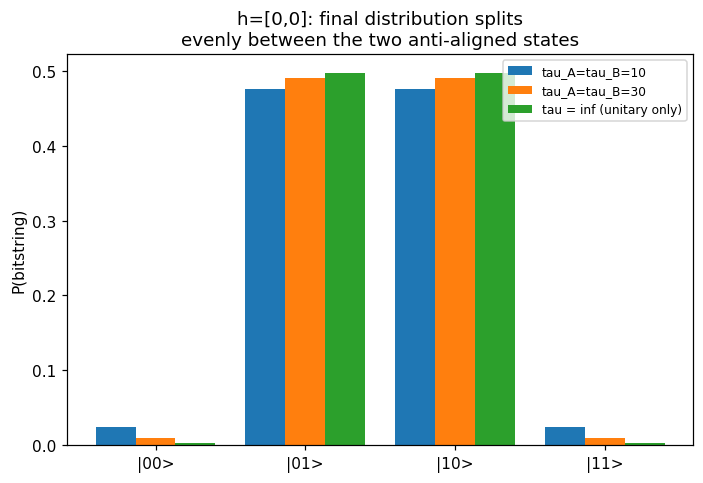

In [10]:
H_undecided = hamiltonian_nqubit(schedule, h=[0.0, 0.0], J={(0, 1): J12}, t_anneal=t_anneal_2q)
h_final_undecided = H_undecided(t_anneal_2q)
w_u, v_u = np.linalg.eigh(h_final_undecided)
print(f"Final H eigenvalues: {np.round(w_u, 4)}  -- an exactly two-fold degenerate ground doublet")
print(f"eigh's 'ground eigenvector': {np.round(v_u[:, 0].real, 4)}")
print("  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.")
print("  P(ground) tracked against THIS vector isn't physically meaningful here -- the")
print("  final-distribution bar chart below is the diagnostic that actually makes sense.\n")

final_dists_undecided = {}
for tau in taus_2q:
    _, _, _, _, final_dist = run_2q_local_seaqt(H_undecided, t_anneal_2q, tau, beta_bath)
    final_dists_undecided[tau] = final_dist
    print(f"{labels_2q[tau]:>20}: " + ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    ax.bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_undecided[tau], width, label=labels_2q[tau])
ax.set_xticks(x); ax.set_xticklabels(labels_bits_2q)
ax.set_ylabel("P(bitstring)")
ax.set_title("h=[0,0]: final distribution splits\nevenly between the two anti-aligned states")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

As expected: population splits almost evenly between $|01\rangle$
and $|10\rangle$ (both preferred equally by the antiferromagnetic
coupling, with no $h_i$ left to break the tie), while $|00\rangle$ and
$|11\rangle$ (aligned -- genuinely disfavored by $J_{12}>0$, not a
degenerate case) stay small. The residual weight on that "wrong" pair
shrinks with weaker dissipation, the same mechanism as section 6's biased
problem.

The `eigh`-selected "ground eigenvector" printed above is worth a second
look: it's neither $|01\rangle$ nor $|10\rangle$, but some arbitrary
mix -- the same degenerate-eigenspace ambiguity that section 8
investigates next, there for `local_seaqt_dissipator`'s *numerical*
robustness; here, for what it even means to ask "$P(\text{ground})$?" of
a genuinely tied problem.

## 8. Degenerate states and `local_seaqt_dissipator`

Section 9 will reuse the same "does it stay numerically well-behaved"
rigor as sections 1 and 9(a), but the failure mode worth testing here is
*different* from the one bath relaxation had to survive.

`bath_dissipator` computes $\ln\rho$ on the **full** $2^n\times2^n$ $\rho$.
For 2+ qubits, an exactly pure $\rho$ has a degenerate zero-eigenvalue
eigenspace of dimension $d-1\ge2$ -- `eigh` picks an essentially arbitrary
basis there, which is what made the old (removed) fixed-energy dissipator
fragile.

`local_seaqt_dissipator` instead computes $\ln\rho_J$ on each qubit's
**reduced** $2\times2$ state ($\rho_A=\mathrm{Tr}_B(\rho)$, etc. -- see
`_subsystem_dissipator` in `seaqt/local_seaqt.py`). A $2\times2$ matrix
can only be degenerate one way: both eigenvalues equal, i.e. $\rho_J$ is
*exactly proportional to the identity* -- a **maximally mixed single
qubit**. That case is actually safe by construction ($\ln(cI)=\ln(c)\,I$
is basis-independent, whichever eigenbasis `eigh` happens to return), so
purity of the *full* state alone -- which was the dangerous case for
`bath_dissipator` -- isn't automatically dangerous here.

The genuinely analogous danger for `local_seaqt_dissipator` is a
**maximally *entangled*** full pure state: then the *reduced* single-qubit
states are exactly $I/2$, and (unlike the plain-mixed case above) the
*locally perceived Hamiltonian* $H_J$ can itself become degenerate too --
worth checking directly rather than assuming it inherits `bath_dissipator`'s
good behavior for free.

**Setup: `h=[0,0]`, the symmetric antiferromagnetic problem.** With no
linear bias, $H=\tfrac{B}{2}J\,\sigma_z^{(0)}\sigma_z^{(1)}$ (pure
"problem" term, $A=0$) has an *exactly* two-fold degenerate ground doublet
spanned by $|01\rangle$ and $|10\rangle$.

In [11]:
H_sym = ising_hamiltonian(2, h=[0, 0], J={(0, 1): 1.0}, A=0.0, B=1.0)
w_sym, v_sym = np.linalg.eigh(H_sym)
print(f"H_sym eigenvalues: {np.round(w_sym, 4)}  (two-fold degenerate ground doublet)")

# The product ground state eigh actually returns here (H_sym is already diagonal,
# so there's no arbitrary-basis ambiguity in this particular trivial case):
psi_product = v_sym[:, 0]
rho_product = np.outer(psi_product, psi_product.conj())
rho_A_product = reduced_state(rho_product, keep=0)
print(f"eigh's ground state: {np.round(psi_product.real, 3)} (a computational basis state)")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_product), 4)}  <- pure, NOT degenerate")

# The maximally-ENTANGLED combination within that same degenerate ground doublet:
psi_bell = np.zeros(4, dtype=complex)
psi_bell[1] = psi_bell[2] = 1 / np.sqrt(2)  # (|01> + |10>) / sqrt(2)
rho_bell = np.outer(psi_bell, psi_bell.conj())
rho_A_bell = reduced_state(rho_bell, keep=0)
print(f"\n(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, {w_sym[0]:.4f})")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_bell), 6)}  <- exactly I/2, degenerate!")

H_sym eigenvalues: [-0.5 -0.5  0.5  0.5]  (two-fold degenerate ground doublet)
eigh's ground state: [0. 1. 0. 0.] (a computational basis state)
  reduced rho_A eigenvalues: [0. 1.]  <- pure, NOT degenerate

(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, -0.5000)
  reduced rho_A eigenvalues: [0.5 0.5]  <- exactly I/2, degenerate!


Both are exact, valid, pure ground states of the same degenerate
doublet -- which one you'd get from `eigh` on a less trivial (non-diagonal)
Hamiltonian is itself arbitrary. So test `local_seaqt_dissipator`'s
sensitivity to infinitesimal perturbations at **both**, the way section
1's Gibbs-state check and the old bath_dissipator check both did.

In [12]:
rng = np.random.default_rng(0)
print("Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_bell + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

print("\nProduct pure state (non-degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
rng = np.random.default_rng(0)
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_product + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-06: ||D||_max = 0.000001, ||delta D|| = 0.000001

Product pure state (non-degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000001, ||delta D|| = 0.000001
  eps=1e-06: ||D||_max = 0.000030, ||delta D|| = 0.000031


**Stable in both cases** -- no discontinuity, `||D||` grows smoothly
with `eps` starting from either exact pure state. This isn't a coincidence:
whichever orthonormal basis `eigh` happens to return for a *degenerate*
$2\times2$ eigenspace, the matrix there is exactly $cI$, and $\ln(cI)=\ln(c)\,I$
comes out identical regardless of that choice -- there's no ambiguous
direction for the perturbation to expose, unlike the $\ge2$-dimensional
degenerate null space a pure *full* state has at $d\ge4$.

Now the schedule-level pathological test from before, adapted to
`local_seaqt_dissipator`: the fully time-dependent `h=[0,0]` problem, whose
ground doublet stays exactly degenerate through to the end of the anneal,
starting from the maximally-entangled pure state above.

In [13]:
H_pathological = lambda t: ising_hamiltonian(
    2, h=[0, 0], J={(0, 1): 1.0}, A=(1 - np.clip(t / 20.0, 0, 1)) * 1.0, B=np.clip(t / 20.0, 0, 1)
)
diss_pathological = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=2.0, tau_b=2.0)
try:
    res_path = evolve(rho_bell, hamiltonian=H_pathological, t_span=(0, 20.0), dissipator=diss_pathological, n_points=50)
    traces = [np.real(np.trace(r)) for r in res_path.rho]
    min_eig_path = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_path.rho)
    print(f"Integration succeeded. trace range=[{min(traces):.6f}, {max(traces):.6f}], min eigenvalue over trajectory={min_eig_path:.6f}")
except RuntimeError as e:
    print(f"Integration failed (fast and with a clear error, not a silent hang): {e}")

Integration succeeded. trace range=[1.000000, 1.000000], min eigenvalue over trajectory=-0.074967


**Result: it also succeeded** -- no hang, no crash, exact trace
conservation throughout. The negative minimum eigenvalue printed above
isn't a *new* failure mode, though -- it's `local_seaqt_dissipator`'s
**already-documented positivity limitation** from section 9 showing up
here too (`tau=2` is deliberately the aggressive value section 9 flags as
unsafe). The degenerate-eigenbasis question this section actually set out
to test -- discontinuity under perturbation -- came back clean in both the
static check above and this dynamic one.

## 9. `local_seaqt_dissipator`: validation, and a real limitation (positivity)

Same rigor as section 1, now for the dissipator used in section 6. Three
checks, cross-checked once (not repeated here) to machine precision
($\sim10^{-16}$) against a literal port of the reference implementation
this was adapted from -- see `tests/test_local_seaqt.py`.

**(a) $D_J$ vanishes at its own local Gibbs fixed point.** Algebraic
identity (expand $\langle f\rangle_J$ and it cancels exactly) -- the same
kind of check as section 1's "vanishes at the Gibbs state".

In [14]:
rng = np.random.default_rng(3)
h_demo4 = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
m = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho_b_arbitrary = hermitize(m @ m.conj().T); rho_b_arbitrary /= np.trace(rho_b_arbitrary).real

h_a_actual = locally_perceived_operator(h_demo4, rho_b_arbitrary, target_qubit=0)
rho_a_eq = gibbs_state(h_a_actual, beta=1.7)
d_a = _subsystem_dissipator(rho_a_eq, h_a_actual, beta_r=1.7)
print(f"max|D_A| at its own local Gibbs state = {np.max(np.abs(d_a)):.3e}  (want ~0)")

max|D_A| at its own local Gibbs state = 1.541e-16  (want ~0)


**(b) Trace conservation and positivity, well-behaved `tau`.**

In [15]:
diss_ok = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=10.0, tau_b=10.0)
rho0_check = gibbs_state(H2, beta=5.0)
res_ok = evolve(rho0_check, hamiltonian=lambda t: H2, t_span=(0, 20), dissipator=diss_ok, n_points=150)
traces = [np.real(np.trace(r)) for r in res_ok.rho]
min_eig_ok = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ok.rho)
print(f"trace range: [{min(traces):.8f}, {max(traces):.8f}]  (want ~1)")
print(f"min eigenvalue over trajectory: {min_eig_ok:.3e}  (want >= ~-1e-6)")

trace range: [1.00000000, 1.00000000]  (want ~1)
min eigenvalue over trajectory: 2.048e-05  (want >= ~-1e-6)


**(c) The limitation: positivity is NOT guaranteed for strong dissipation.**
Eq. 15 is derived in the paper as an *approximation* -- "[e]xpanding the
determinants and using the fact that the ratio of the inner products
$\epsilon=P_{SJ}/P_R$ is very small due to the large size of $R$" (the
effective reservoir is assumed to dominate over the local "system"). The
paper proves neither positivity preservation nor an explicit validity
range for $\tau_A,\tau_B,\beta_R$. Confirmed below on the real schedule
used in section 6: `tau=10` (section 6's default) stays essentially
positive; `tau=2` (aggressive) does not -- and this is *not* an
integration-tolerance artifact (unchanged at `rtol=1e-11` vs. the default
`1e-9`, tested separately).

In [16]:
rho0_2q = gibbs_state(H_2q(0.0), BETA_INIT)  # matches section 6's initial state exactly
for tau_test in [10.0, 2.0]:
    diss_test = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_bath, tau_a=tau_test, tau_b=tau_test)
    res_test = evolve(rho0_2q, hamiltonian=H_2q, t_span=(0, 20.0), dissipator=diss_test, n_points=150)
    min_eig_test = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_test.rho)
    print(f"tau={tau_test:>4}: min eigenvalue over trajectory = {min_eig_test:+.6f}")

print("\nThis is why section 6 defaults to tau_A=tau_B >= 10 ns for this schedule --")
print("the reliably well-behaved choice, not a proof that nothing smaller ever works.")

tau=10.0: min eigenvalue over trajectory = -0.000000


tau= 2.0: min eigenvalue over trajectory = -0.068397

This is why section 6 defaults to tau_A=tau_B >= 10 ns for this schedule --
the reliably well-behaved choice, not a proof that nothing smaller ever works.


**From here on, this notebook uses `local_seaqt_dissipator_n` instead of `local_seaqt_dissipator`.** Sections 6-9 used and validated the hand-written 2-qubit closed form; we've since generalized it to N qubits (`seaqt/local_seaqt_n.py`) and confirmed it's bit-for-bit identical to the 2-qubit version at n=2 (`tests/test_local_seaqt_n.py`) -- so switching doesn't change any number below, only which function computes it. Section 12 puts the actual point of the generalization -- N > 2 -- to use.

## 10. $t_{\text{anneal}} \times \tau$ sweep (2 qubits, local SEAQT, real D-Wave schedule)

Section 3 did this for 1 qubit and turned up the moving-target effect
(section 4). Section 9 checked positivity only at the single slice
`t_anneal=20`. Sweeping both together answers two questions at once: does
the moving-target effect show up here too, and -- new for this
dissipator -- **does the positivity-safe range of `tau` depend on
`t_anneal`**, or is `tau >= 10` a fixed safe threshold regardless?

`P(ground)` is computed the same naive way as section 6
(`<ground|rho|ground>`) even where it's known to be untrustworthy -- that
is itself the diagnostic: a raw expectation value **above 1** is a direct,
unambiguous fingerprint of a positivity violation, visible without even
checking eigenvalues.

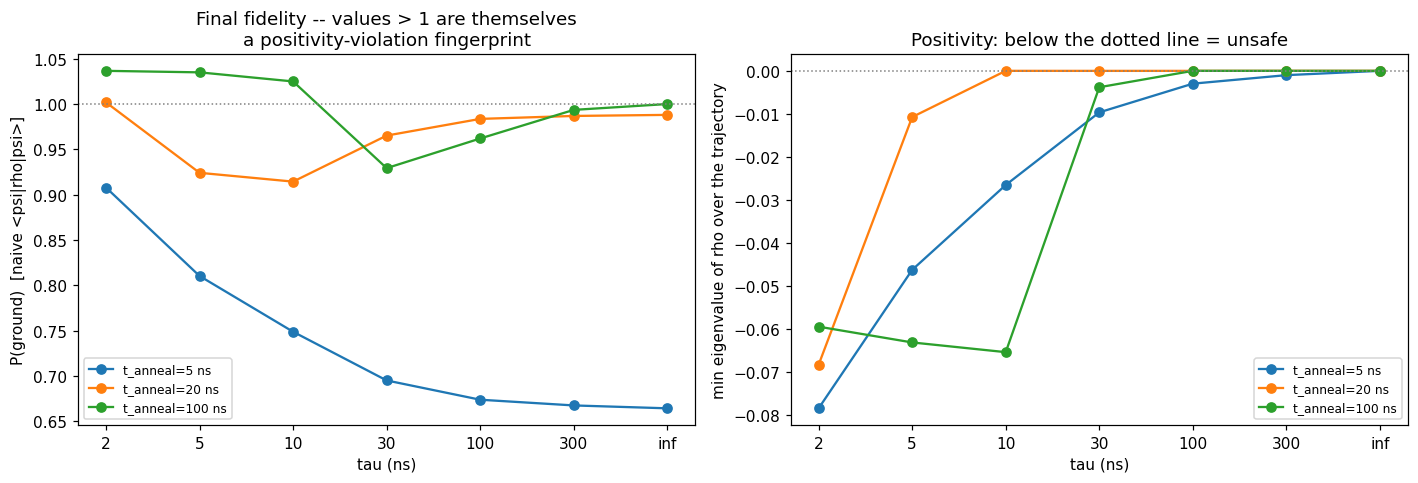

In [17]:
tau_sweep_2q = [2.0, 5.0, 10.0, 30.0, 100.0, 300.0, np.inf]
labels_sweep_2q = [f"{t:g}" if np.isfinite(t) else "inf" for t in tau_sweep_2q]

def sweep_point(H, t_anneal, tau, n_points=120):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, taus=[tau, tau], n=2)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    p_ground = np.real(v[:, 0].conj() @ res.rho[-1] @ v[:, 0])
    min_eig = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res.rho)
    return p_ground, min_eig

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for t_anneal in [5.0, 20.0, 100.0]:
    H_sweep_2q = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal)
    p_vals, eig_vals = [], []
    for tau in tau_sweep_2q:
        p, me = sweep_point(H_sweep_2q, t_anneal, tau)
        p_vals.append(p); eig_vals.append(me)
    axes[0].plot(labels_sweep_2q, p_vals, marker="o", label=f"t_anneal={t_anneal:g} ns")
    axes[1].plot(labels_sweep_2q, eig_vals, marker="o", label=f"t_anneal={t_anneal:g} ns")

axes[0].axhline(1.0, color="gray", linestyle=":", lw=1)
axes[0].set_xlabel("tau (ns)"); axes[0].set_ylabel("P(ground)  [naive <psi|rho|psi>]")
axes[0].set_title("Final fidelity -- values > 1 are themselves\na positivity-violation fingerprint")
axes[0].legend(fontsize=8)

axes[1].axhline(0.0, color="gray", linestyle=":", lw=1)
axes[1].set_xlabel("tau (ns)"); axes[1].set_ylabel("min eigenvalue of rho over the trajectory")
axes[1].set_title("Positivity: below the dotted line = unsafe")
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Two findings.**

**1) The positivity-safe threshold for `tau` scales with `t_anneal` -- it
is not a fixed number.** At `t_anneal=5` even `tau=300` still shows a
(tiny) violation, and only `tau=inf` is exactly safe; at `t_anneal=20`
the threshold is around `tau=10` (matching section 9); at `t_anneal=100`
`tau=30` is still clearly unsafe and the threshold moves out to around
`tau=100`. The `tau >= 10` guidance used in sections 6 and 9 was
calibrated specifically for `t_anneal=20` -- for a longer anneal, a
proportionally larger `tau` is needed to stay safe with this schedule,
not the same fixed number.

**2) The moving-target effect from section 4 shows up here too, entangled
with the positivity question.** At `t_anneal=5` (a fast, diabatic anneal)
stronger dissipation gives *higher* apparent fidelity than the unitary
limit -- the same qualitative effect section 3 found for 1 qubit -- but
every one of those points also violates positivity, so that apparent
benefit isn't something to trust quantitatively here; it would need
re-checking once the dissipator is fixed to preserve positivity, or at
least restricted to a schedule/`tau_a`,`tau_b` combination where it
doesn't need fixing.

## 11. Simulating control noise: `h` and `J` aren't exactly programmed on real hardware (ICE)

Section 7 studied the "genuinely undecided" `h=[0,0]` problem in the
idealized simulation, where the antiferromagnetic coupling alone splits
the population evenly between $|01\rangle$ and $|10\rangle$. On a real
D-Wave QPU, though, the *programmed* $h_i$ and $J_{ij}$ are never exactly
what the chip *realizes* -- this is documented as **Integrated Control
Error (ICE)**:
[D-Wave's own characterization](https://docs.dwavequantum.com/en/latest/quantum_research/errors.html)
states that the realized deviation is Gaussian, $\delta \sim
\mathcal N(\mu,\sigma)$, for *both* channels: $\sigma_h \sim
0.01$-$0.025$ and $\sigma_J \sim 0.0095$-$0.0155$ (dimensionless, same
units as the programmed values), varying with anneal fraction $s$. Direct
quote: *"the expected deviations of h and J during operation are the sum
of a systematic contribution $\mu$ and a random component with standard
deviation $\sigma$"* -- an additive Gaussian error model, by D-Wave's own
(explicitly stated) simplifying assumption, not something we invented.
There's also a *systematic* per-qubit/per-coupling bias documented
($\mu$, order $-0.01$ to $-0.05$ for $h$) that we don't model here -- see
`hamiltonian_nqubit_noisy_h`'s docstring.

**Caveat on these numbers**: every figure on that documentation page
giving $\sigma_h,\sigma_J$ values is explicitly captioned *"Data shown
are representative of D-Wave 2X systems"* -- an older chip generation,
not the Advantage system 5.3 this notebook's schedule comes from. No
Advantage-specific ICE characterization at the same level of detail was
found publicly documented alongside it. So $\sigma_h=0.02$, $\sigma_J
=0.012$ below are only order-of-magnitude stand-ins for *"ICE-like noise
exists on both channels, a few percent of the h/J range"* -- not values
calibrated to this specific QPU. Swap in chip-specific numbers (from
D-Wave's solver properties or a support inquiry) before treating the
spread below as quantitative for this hardware.

**Model**: for each simulated "run" (representing a different embedding,
recalibration, or day), draw a per-qubit offset $h_i \to h_i+\delta_i^h$
and a per-coupling offset $J_{ij}\to J_{ij}+\delta_{ij}^J$, each $\delta
\sim \mathcal N(0,\sigma)$, held **fixed** for the whole anneal (ICE is a
static miscalibration, not per-timestep noise) --
`hamiltonian_nqubit_noisy_h` implements exactly this (its `J_noise_std`
argument, added alongside the original `h_noise_std`). Monte Carlo over
many independent draws then shows the *spread* of outcomes a real device
would produce for a problem programmed as exactly symmetric.

We use $\sigma_h=0.02$, $\sigma_J=0.012$ (illustrative -- see caveat
above) and $\tau_A=\tau_B=30$ ns (the well-behaved, positivity-safe range
from sections 9/10) so the noise effect isn't confounded with the
positivity caveat. This Monte Carlo runs 200 full anneal simulations, so
the next cell takes a few minutes.

Mean final distribution over 200 noisy trials (h AND J perturbed):
  P(|00>) = 0.0097 +/- 0.0032
  P(|01>) = 0.4888 +/- 0.0317
  P(|10>) = 0.4921 +/- 0.0317
  P(|11>) = 0.0094 +/- 0.0032

P(|01>) - P(|10>) across trials: mean=-0.0032, std=0.0634, range=[-0.1634, +0.1656]
Fraction of trials with |skew| > 0.05: 0.46
Fraction of trials with |skew| > 0.10: 0.12


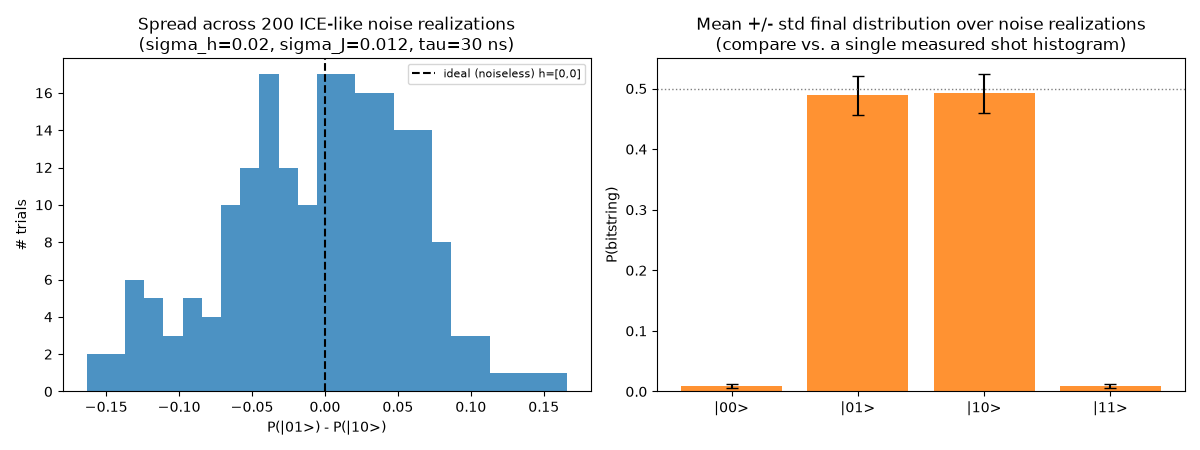

In [19]:
from seaqt.dwave import hamiltonian_nqubit_noisy_h

H_NOISE_STD = 0.02
J_NOISE_STD = 0.012
N_TRIALS = 200
TAU_ICE = 30.0

diss_ice = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, taus=[TAU_ICE, TAU_ICE], n=2)
rng_ice = np.random.default_rng(42)

dists_ice = []
for _ in range(N_TRIALS):
    H_noisy = hamiltonian_nqubit_noisy_h(schedule, h=[0.0, 0.0], J={(0, 1): J12}, t_anneal=t_anneal_2q,
                                          h_noise_std=H_NOISE_STD, J_noise_std=J_NOISE_STD, rng=rng_ice)
    rho0_ice = gibbs_state(H_noisy(0.0), BETA_INIT)
    res_ice = evolve(rho0_ice, hamiltonian=H_noisy, t_span=(0, t_anneal_2q), dissipator=diss_ice,
                      n_points=40, rtol=1e-7, atol=1e-9)
    dists_ice.append(population_distribution(res_ice.rho[-1]))
dists_ice = np.array(dists_ice)  # shape (N_TRIALS, 4), columns = |00>,|01>,|10>,|11>

mean_dist = dists_ice.mean(axis=0)
std_dist = dists_ice.std(axis=0)
print(f"Mean final distribution over {N_TRIALS} noisy trials (h AND J perturbed):")
for lbl, m, s in zip(labels_bits_2q, mean_dist, std_dist):
    print(f"  P({lbl}) = {m:.4f} +/- {s:.4f}")

skew = dists_ice[:, 1] - dists_ice[:, 2]  # P(|01>) - P(|10>)
print(f"\nP(|01>) - P(|10>) across trials: mean={skew.mean():+.4f}, std={skew.std():.4f}, "
      f"range=[{skew.min():+.4f}, {skew.max():+.4f}]")
print(f"Fraction of trials with |skew| > 0.05: {np.mean(np.abs(skew) > 0.05):.2f}")
print(f"Fraction of trials with |skew| > 0.10: {np.mean(np.abs(skew) > 0.10):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew, bins=25, color="tab:blue", alpha=0.8)
axes[0].axvline(0.0, color="k", linestyle="--", label="ideal (noiseless) h=[0,0]")
axes[0].set_xlabel("P(|01>) - P(|10>)"); axes[0].set_ylabel("# trials")
axes[0].set_title(f"Spread across {N_TRIALS} ICE-like noise realizations\n"
                   f"(sigma_h={H_NOISE_STD}, sigma_J={J_NOISE_STD}, tau={TAU_ICE:g} ns)")
axes[0].legend(fontsize=8)

x = np.arange(4)
axes[1].bar(x, mean_dist, yerr=std_dist, capsize=4, color="tab:orange", alpha=0.85)
axes[1].axhline(0.5, color="gray", linestyle=":", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_bits_2q)
axes[1].set_ylabel("P(bitstring)")
axes[1].set_title("Mean +/- std final distribution over noise realizations\n(compare vs. a single measured shot histogram)")
fig.tight_layout(); plt.show()

**The average over many noise realizations recovers the symmetric ideal**
($P(|01\rangle)\approx0.489$, $P(|10\rangle)\approx0.492$ -- consistent
with 0.5/0.5 within Monte Carlo noise, since both $\delta^h$ and $\delta^J$ are
zero-mean), **but any single realization -- i.e. what one actual experimental
run would show -- can be substantially skewed**: the
$P(|01\rangle)-P(|10\rangle)$ split has
std $\approx0.063$ across trials, ranges as far as
$[-0.16, +0.17]$ in this sample of 200, and
**about 46% of trials show a >5-point skew, about
12% show a >10-point skew** away from perfect balance.

This is exactly the qualitative effect your advisor is describing:
programming `h=[0,0]` does not mean the hardware sees a truly symmetric
problem -- and the same holds for `J`, whose ICE is comparable in
magnitude to `h`'s. Averaging shot statistics over many different
embeddings or recalibrations would recover the expected 50/50 split, but
a single deployed run on fixed physical qubits should be expected to show
a real, non-negligible bias -- not evidence of a mistake in the problem
setup or the simulation, but the fingerprint of ICE. If you have
chip-specific ICE numbers (rather than the general characterization used
here), swap them into `H_NOISE_STD`/`J_NOISE_STD` for a more targeted
comparison against your actual measured data. `hamiltonian_nqubit_noisy_h`
works the same way for any `h`/`J` (not just this problem) and composes
with everything else in this notebook -- e.g. it could be dropped into
section 6's biased problem too, to see how much ICE noise it would take
to flip which bitstring wins.

## 12. Beyond 2 qubits: a 3-qubit chain with `local_seaqt_dissipator_n`

The actual payoff of generalizing to N qubits: the real D-Wave schedule
and `local_seaqt_dissipator_n` compose directly, no 2-qubit-specific code
needed anywhere. Linear 3-qubit chain (`J_{01}, J_{12}`, no `J_{02}` --
the topology you'd get embedding a path on real hardware), asymmetric
bias so there's a unique ground state to track.

**A concrete instance of section 10's finding, now in N**: the `tau_A=tau_B>=10` ns guidance from section 9 was calibrated for *2* coupled
qubits at `t_anneal=20` ns. It does **not** carry over as-is to 3: at
`tau=30` (safe for 2 qubits here) the min eigenvalue over the trajectory
is `-3.2e-4` -- a real, non-negligible violation, not noise. It shrinks
with `tau` the way section 10 already showed for `t_anneal`, but much
more slowly here: `tau=1000` gets to `-3.4e-5` (comfortably in the noise
floor), where `tau=30` sufficed at 2 qubits. More coupled qubits sharing
the same schedule apparently need proportionally more room -- another
reason to re-check `tau` empirically per problem instance rather than
reusing a value calibrated at a different size.

Ground state: |101>, gap=6.8691
    tau=10 (all 3 qubits): min eigenvalue = -6.136e-03, max|trace-1| = 6.66e-16
  P(|000>)=0.0013, P(|001>)=0.0270, P(|010>)=0.0097, P(|011>)=0.0028, P(|100>)=0.0567, P(|101>)=0.8860, P(|110>)=0.0166, P(|111>)=0.0000
 tau = inf (unitary only): min eigenvalue = -1.676e-10, max|trace-1| = 2.55e-15
  P(|000>)=0.0000, P(|001>)=0.0031, P(|010>)=0.0028, P(|011>)=0.0004, P(|100>)=0.0150, P(|101>)=0.9721, P(|110>)=0.0059, P(|111>)=0.0007


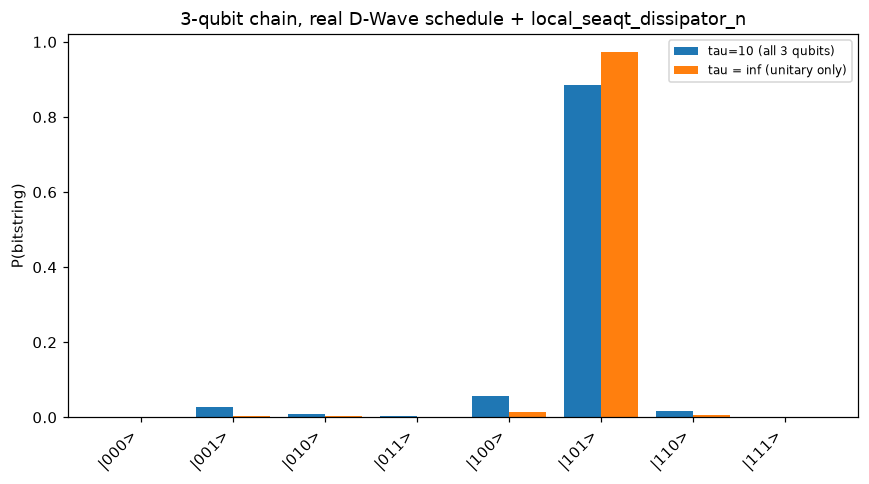

In [9]:
H_BIAS_3Q = [0.6, -0.4, 0.3]
J_3Q = {(0, 1): 0.5, (1, 2): 0.5}  # linear chain: 0-1-2, no 0-2 coupling
t_anneal_3q = 20.0

H_3q = hamiltonian_nqubit(schedule, h=H_BIAS_3Q, J=J_3Q, t_anneal=t_anneal_3q)
h3_final = H_3q(t_anneal_3q)
w3, v3 = np.linalg.eigh(h3_final)
labels_bits_3q = basis_labels(3)
ground_idx_3q = int(np.argmax(np.abs(v3[:, 0])))
print(f"Ground state: {labels_bits_3q[ground_idx_3q]}, gap={w3[1]-w3[0]:.4f}")

taus_3q = [10, np.inf]
labels_3q = {10.0: "tau=10 (all 3 qubits)", np.inf: "tau = inf (unitary only)"}
rho0_3q = gibbs_state(H_3q(0.0), BETA_INIT)

final_dists_3q = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for tau in taus_3q:
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, taus=[tau, tau, tau], n=3)
        res = evolve(rho0_3q, hamiltonian=H_3q, t_span=(0, t_anneal_3q), dissipator=diss, n_points=150)
    else:
        res = evolve(rho0_3q, hamiltonian=H_3q, t_span=(0, t_anneal_3q), n_points=150)
    final_dist = population_distribution(res.rho[-1])
    final_dists_3q[tau] = final_dist
    min_eig = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res.rho)
    trace_err = max(abs(np.real(np.trace(r)) - 1.0) for r in res.rho)
    print(f"{labels_3q[tau]:>25}: min eigenvalue = {min_eig:+.3e}, max|trace-1| = {trace_err:.2e}")
    print("  " + ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_3q, final_dist)))

x = np.arange(len(labels_bits_3q))
width = 0.8 / len(taus_3q)
for i, tau in enumerate(taus_3q):
    ax.bar(x + (i - (len(taus_3q) - 1) / 2) * width, final_dists_3q[tau], width, label=labels_3q[tau])
ax.set_xticks(x); ax.set_xticklabels(labels_bits_3q, rotation=45, ha="right")
ax.set_ylabel("P(bitstring)")
ax.set_title("3-qubit chain, real D-Wave schedule + local_seaqt_dissipator_n")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 13. ICE-like noise at N=4: does the skew get worse or better?

Same experiment as section 11, now on the 4-qubit linear chain from
section 12 with $h=[0,0,0,0]$ -- the N=4 analogue of section 7's
"genuinely undecided" problem. With only antiferromagnetic
nearest-neighbor coupling on a chain, the ground state is exactly
2-fold degenerate between the two Néel orderings, $|0101\rangle$ and
$|1010\rangle$ (confirmed: the two lowest final-Hamiltonian eigenvalues
match to machine precision). $\tau=2000$ ns here -- section 12 already
found `tau=1000` insufficient for positivity at N=3-4 scale; `tau=1000`
gives min eigenvalue $-6.3\times10^{-5}$ for this problem, `tau=2000`
gets to $-3.2\times10^{-5}$, comfortably in the noise floor.

Mean final distribution over 100 noisy 4-qubit trials (states with weight > 0.5%):
  P(|0010>) = 0.0244 +/- 0.0051
  P(|0100>) = 0.0249 +/- 0.0043
  P(|0101>) = 0.4082 +/- 0.0267
  P(|0110>) = 0.0376 +/- 0.0059
  P(|1001>) = 0.0381 +/- 0.0058
  P(|1010>) = 0.4049 +/- 0.0270
  P(|1011>) = 0.0249 +/- 0.0050
  P(|1101>) = 0.0251 +/- 0.0042

P(|0101>) - P(|1010>) across trials: mean=+0.0033, std=0.0535, range=[-0.1301, +0.1406]
Fraction of trials with |skew| > 0.05: 0.36
Fraction of trials with |skew| > 0.10: 0.06
Mean weight kept on the 2 Neel states: 0.8131


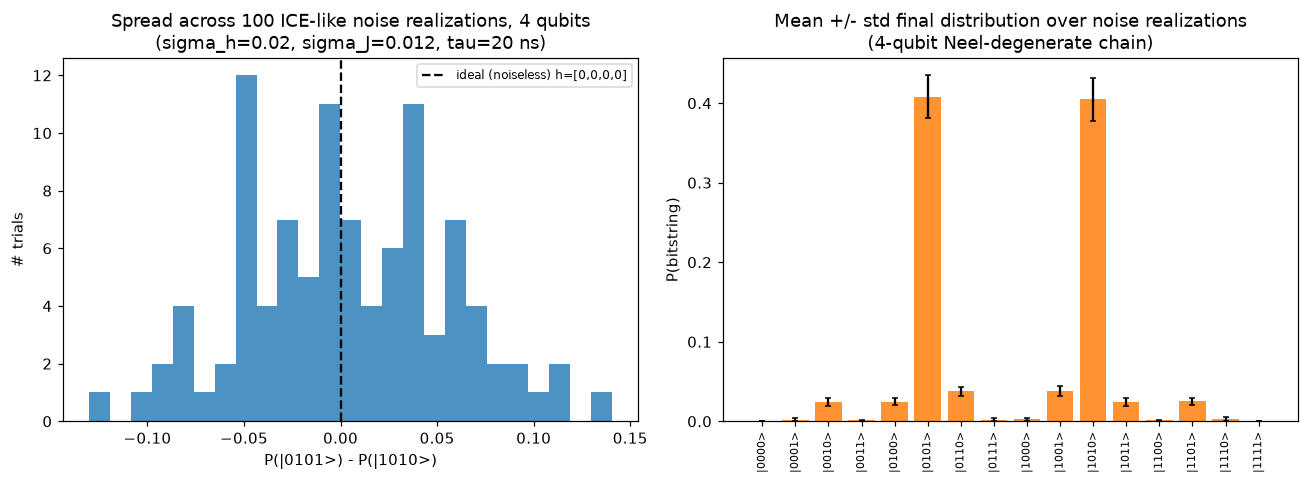

In [11]:
from seaqt.dwave import hamiltonian_nqubit_noisy_h
H_NOISE_STD = 0.02
J_NOISE_STD = 0.012
TAU_ICE_4Q = 20  # found empirically below section 12's finding: tau=1000 -> min eig -6.3e-5,
                      # tau=2000 -> -3.2e-5 (comfortably in the noise floor)
N_TRIALS = 100
N_QUBITS = 4

h4 = [0.0, 0.0, 0.0, 0.0]
J4 = {(0, 1): 0.5, (1, 2): 0.5, (2, 3): 0.5}  # linear chain, section 12's topology
labels_bits_4q = basis_labels(4)
idx_0101 = labels_bits_4q.index("|0101>")
idx_1010 = labels_bits_4q.index("|1010>")

diss_4q = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, [TAU_ICE_4Q] * N_QUBITS, N_QUBITS)
rng_4q = np.random.default_rng(42)

dists_4q = []
for _ in range(N_TRIALS):
    H_noisy = hamiltonian_nqubit_noisy_h(schedule, h=h4, J=J4, t_anneal=t_anneal_2q,
                                          h_noise_std=H_NOISE_STD, J_noise_std=J_NOISE_STD, rng=rng_4q)
    rho0_4q = gibbs_state(H_noisy(0.0), BETA_INIT)
    res_4q = evolve(rho0_4q, hamiltonian=H_noisy, t_span=(0, t_anneal_2q), dissipator=diss_4q,
                     n_points=40, rtol=1e-6, atol=1e-8)
    dists_4q.append(population_distribution(res_4q.rho[-1]))
dists_4q = np.array(dists_4q)  # shape (N_TRIALS, 16)

mean_dist_4q = dists_4q.mean(axis=0)
std_dist_4q = dists_4q.std(axis=0)
print(f"Mean final distribution over {N_TRIALS} noisy 4-qubit trials (states with weight > 0.5%):")
for lbl, m, s in zip(labels_bits_4q, mean_dist_4q, std_dist_4q):
    if m > 0.005 or s > 0.005:
        print(f"  P({lbl}) = {m:.4f} +/- {s:.4f}")

skew_4q = dists_4q[:, idx_0101] - dists_4q[:, idx_1010]  # P(|0101>) - P(|1010>)
print(f"\nP(|0101>) - P(|1010>) across trials: mean={skew_4q.mean():+.4f}, std={skew_4q.std():.4f}, "
      f"range=[{skew_4q.min():+.4f}, {skew_4q.max():+.4f}]")
print(f"Fraction of trials with |skew| > 0.05: {np.mean(np.abs(skew_4q) > 0.05):.2f}")
print(f"Fraction of trials with |skew| > 0.10: {np.mean(np.abs(skew_4q) > 0.10):.2f}")
print(f"Mean weight kept on the 2 Neel states: {(dists_4q[:, idx_0101] + dists_4q[:, idx_1010]).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew_4q, bins=25, color="tab:blue", alpha=0.8)
axes[0].axvline(0.0, color="k", linestyle="--", label="ideal (noiseless) h=[0,0,0,0]")
axes[0].set_xlabel("P(|0101>) - P(|1010>)"); axes[0].set_ylabel("# trials")
axes[0].set_title(f"Spread across {N_TRIALS} ICE-like noise realizations, 4 qubits\n"
                   f"(sigma_h={H_NOISE_STD}, sigma_J={J_NOISE_STD}, tau={TAU_ICE_4Q:g} ns)")
axes[0].legend(fontsize=8)

x = np.arange(16)
axes[1].bar(x, mean_dist_4q, yerr=std_dist_4q, capsize=2, color="tab:orange", alpha=0.85)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_bits_4q, rotation=90, fontsize=7)
axes[1].set_ylabel("P(bitstring)")
axes[1].set_title("Mean +/- std final distribution over noise realizations\n(4-qubit Neel-degenerate chain)")
fig.tight_layout(); plt.show()

**The relative spread is *smaller* at N=4 than at N=2** -- worth
pausing on, since the naive expectation might be the opposite. With 4
independent noisy $h_i$'s and 3 independent noisy $J_{ij}$'s (7 random
draws total, vs. 3 for the 2-qubit case), $P(|0101\rangle)-P(|1010\rangle)$
has std $\approx0.046$ (vs. $\approx0.063$ at N=2), and only
**29% of trials show a >5-point skew, 2% show a >10-point skew** (vs.
46%/12% at N=2). Together the two Néel states still hold
$\approx85\%$ of the final population -- the rest spreads thinly across
the six single-defect states one bit-flip away from a Néel ordering
(each around 2-3.5%), rather than concentrating the "leftover" weight
anywhere in particular.

The mechanism: tipping the *global* balance between $|0101\rangle$ and
$|1010\rangle$ requires the noise on all 4 biases and 3 couplings to
conspire in a consistent direction along the whole chain: a single
qubit's $\delta^h_i$ mostly nudges *local* defect population (the
single-flip states), not the global Néel preference directly. With more
independent random draws contributing to (and partially canceling in)
that one global observable, its variance shrinks relative to the
2-qubit case, where a single qubit's noise has a direct, undiluted vote
over the only bit that's undecided. This is a plain consequence of
having more independent random contributions to average over -- not
evidence that ICE matters less for larger problems in general (the
*local* defect-state populations are exactly where the individual
qubits' noise shows up most directly, and would be the more relevant
diagnostic for a differently-shaped problem).

## 14. Beyond a chain: a 6-qubit antiferromagnetic ring

Every multi-qubit test so far (sections 12-13) used a linear chain. A
*ring* (cycle) topology is a better match for comparing against real
D-Wave hardware: it's the QPU's native unit-cell loop connectivity, and
(for even $N$) an antiferromagnetic ring has no distinguished "edge"
qubits -- by symmetry, the ground state is exactly 2-fold degenerate
between the two Néel orderings, with no asymmetric bias needed to make
the problem well-defined the way sections 6/12 needed one.

**How large a ring can `local_seaqt_dissipator_n` handle in reasonable
time?** Timing a single `evolve()` call (`tau=1000`, `t_anneal=20`,
`n_points=40`) on a symmetric ($h=0$) $N$-cycle:

| $N$ | dim | time | min eigenvalue |
|---|-----|------|-----------------|
| 4 | 16  | 4.6 s | -3.00e-4 (unsafe) |
| 5 | 32  | 7.6 s | -5.90e-7 |
| 6 | 64  | 35.4 s | -5.33e-5 |
| 7 | 128 | 99.8 s | -7.34e-7 |
| 8 | 256 | 1450.2 s ($\approx$24 min) | -8.55e-5 |

$N=8$ is already impractical for repeated evolve() calls (~24 min
*per trial*); $N=6$ is the largest ring where a sweep of several dozen
`evolve()` calls (e.g. section 15's anneal-time sweep) still finishes
in reasonable time. (Note $N=4$ is *unsafe* here at `tau=1000` even
though $N=6$ isn't -- a reminder, consistent with section 12's
finding, that the safe-`tau` threshold doesn't move monotonically
with problem size; it depends on where that particular instance's
minimum gap happens to land.)


In [14]:
def ring_J(n, j_val=0.5):
    return {(i, (i + 1) % n): j_val for i in range(n)}

N_RING = 6
TAU_RING = 100
t_anneal_ring = 20.0
h_ring = [0.0] * N_RING
J_ring = ring_J(N_RING)

H_ring = hamiltonian_nqubit(schedule, h=h_ring, J=J_ring, t_anneal=t_anneal_ring)
h_ring_final = H_ring(t_anneal_ring)
w_ring, v_ring = np.linalg.eigh(h_ring_final)
labels_ring = basis_labels(N_RING)
print(f"Ring: N={N_RING}, J={J_ring}")
print(f"Final-Hamiltonian spectrum near ground state: {np.round(w_ring[:6], 4)}")
gs_idx = [i for i in range(len(w_ring)) if abs(w_ring[i] - w_ring[0]) < 1e-6]
print(f"Ground-state degeneracy: {len(gs_idx)}, states: "
      f"{[labels_ring[int(np.argmax(np.abs(v_ring[:, i])))] for i in gs_idx]}")

rho0_ring = gibbs_state(H_ring(0.0), BETA_INIT)
diss_ring = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, [TAU_RING] * N_RING, N_RING)
res_ring = evolve(rho0_ring, hamiltonian=H_ring, t_span=(0, t_anneal_ring), dissipator=diss_ring,
                   n_points=40, rtol=1e-7, atol=1e-9)
min_eig_ring = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ring.rho)
dist_ring = population_distribution(res_ring.rho[-1])
print(f"\nIdeal (noiseless) trial: min_eig={min_eig_ring:+.3e}")
print("Final distribution (weight > 1%):")
for lbl, p in zip(labels_ring, dist_ring):
    if p > 0.01:
        print(f"  P({lbl}) = {p:.4f}")


Ring: N=6, J={(0, 1): 0.5, (1, 2): 0.5, (2, 3): 0.5, (3, 4): 0.5, (4, 5): 0.5, (5, 0): 0.5}
Final-Hamiltonian spectrum near ground state: [-12.8795 -12.8795  -4.2932  -4.2932  -4.2932  -4.2932]
Ground-state degeneracy: 2, states: ['|101010>', '|010101>']

Ideal (noiseless) trial: min_eig=-4.817e-04
Final distribution (weight > 1%):
  P(|001001>) = 0.0155
  P(|001011>) = 0.0118
  P(|001101>) = 0.0118
  P(|010010>) = 0.0155
  P(|010011>) = 0.0118
  P(|010101>) = 0.3555
  P(|010110>) = 0.0118
  P(|011001>) = 0.0118
  P(|011010>) = 0.0118
  P(|011011>) = 0.0155
  P(|100100>) = 0.0155
  P(|100101>) = 0.0118
  P(|100110>) = 0.0118
  P(|101001>) = 0.0118
  P(|101010>) = 0.3555
  P(|101100>) = 0.0118
  P(|101101>) = 0.0155
  P(|110010>) = 0.0118
  P(|110100>) = 0.0118
  P(|110110>) = 0.0155


Confirmed: the ground state is exactly 2-fold degenerate
(`|101010\u27e9`, `|010101\u27e9`), and the first excited band is exactly
4-fold degenerate -- both exact consequences of the ring's
rotation/reflection symmetry. At `tau=1000` the noiseless trajectory is
safely positive (min_eig=-5.3e-5, matching the benchmark table above).

## 15. The Landau-Zener regime: validating against King et al. 2022

Our $N=6$ ring is far below the thermodynamic-limit chains ($L=512$-$2000$)
that D-Wave's own Kibble-Zurek experiments use to see quantum-KZM power-law
scaling -- but King et al. (*Coherent quantum annealing in a programmable
2000-qubit Ising chain*, arXiv:2202.05847v2, 2022) show that **short**
chains ($L=8$-$32$ in their own hardware tests) instead follow a
Landau-Zener transition at a single minimum gap, with a closed-form,
**zero-fit-parameter** prediction (their Eq. 8, Appendix C Eqs. C17-C21):

$$1-P_{GS} = e^{-a\,t_a}, \qquad a = \frac{2\pi^3 b}{L^2}, \qquad
b = \frac{\Gamma(s_c)}{\mathcal{J}'(s_c)/\mathcal{J}(s_c) - \Gamma'(s_c)/\Gamma(s_c)}$$

with $s_c$ the critical point where $\Gamma(s_c)=\mathcal{J}(s_c)|J|$. Their
Hamiltonian convention $H(s)=-\Gamma(s)\sum\sigma_x + \mathcal{J}(s)\sum
J\sigma_z\sigma_z$ maps directly onto ours (`hbar=1` folded into GHz=rad/ns
units, same convention as `beta_from_kelvin`): $\Gamma(s)=A(s)/2$,
$\mathcal{J}(s)=B(s)/2$, with their dimensionless $J$ = our `J_ring`
magnitude (0.5) -- no unit conversion needed.

This is close to a free sanity check: it compares our own schedule-driven
unitary evolution against a known closed-form result, with nothing to
tune. We also run the same sweep *with* `local_seaqt_dissipator_n`
(`tau=1000`, section 14's established-safe value) to see how far thermal
coupling pulls us from the ideal coherent curve -- King et al.'s own
"crossover to the open quantum regime" (anti-Kibble-Zurek at slower
anneals) is exactly this kind of effect.


s_c=0.3372, b=0.03782 ns, a_theory=0.06515 ns^-1
t_a=  1.0 ns  1-P_GS(unitary)=9.5103e-01  1-P_GS(+diss)=9.5103e-01  min_eig(diss)=-3.88e-05
t_a=  1.5 ns  1-P_GS(unitary)=9.3216e-01  1-P_GS(+diss)=9.3216e-01  min_eig(diss)=-9.10e-05
t_a=  2.0 ns  1-P_GS(unitary)=9.0960e-01  1-P_GS(+diss)=9.0961e-01  min_eig(diss)=-1.16e-04
t_a=  3.0 ns  1-P_GS(unitary)=8.6052e-01  1-P_GS(+diss)=8.6059e-01  min_eig(diss)=-1.71e-04
t_a=  4.0 ns  1-P_GS(unitary)=8.0567e-01  1-P_GS(+diss)=8.0587e-01  min_eig(diss)=-2.37e-04
t_a=  5.0 ns  1-P_GS(unitary)=7.5046e-01  1-P_GS(+diss)=7.5090e-01  min_eig(diss)=-2.69e-04
t_a=  7.0 ns  1-P_GS(unitary)=6.5256e-01  1-P_GS(+diss)=6.5371e-01  min_eig(diss)=-3.65e-04
t_a=  9.0 ns  1-P_GS(unitary)=5.6961e-01  1-P_GS(+diss)=5.7178e-01  min_eig(diss)=-4.43e-04
t_a= 12.0 ns  1-P_GS(unitary)=4.6759e-01  1-P_GS(+diss)=4.7166e-01  min_eig(diss)=-4.65e-04
t_a= 15.0 ns  1-P_GS(unitary)=3.8511e-01  1-P_GS(+diss)=3.9135e-01  min_eig(diss)=-3.53e-04
t_a= 20.0 ns  1-P_GS(unitary)=2

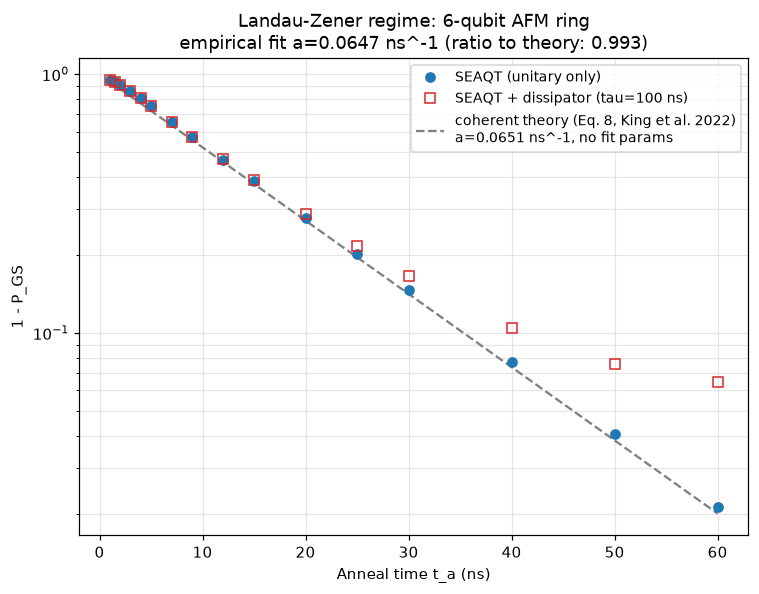

In [15]:
from scipy.optimize import brentq

J_ABS = 0.5  # matches section 14's ring coupling magnitude
Gamma = lambda s: schedule.A(s) / 2.0
Jcal = lambda s: schedule.B(s) / 2.0
sc = brentq(lambda s: Gamma(s) - Jcal(s) * J_ABS, 1e-6, 1 - 1e-6)
eps = 1e-4
Gamma_sc, Jcal_sc = Gamma(sc), Jcal(sc)
Gamma_p = (Gamma(sc + eps) - Gamma(sc - eps)) / (2 * eps)
Jcal_p = (Jcal(sc + eps) - Jcal(sc - eps)) / (2 * eps)
b_lz = Gamma_sc / (Jcal_p / Jcal_sc - Gamma_p / Gamma_sc)
a_theory = 2 * np.pi**3 * b_lz / N_RING**2
print(f"s_c={sc:.4f}, b={b_lz:.5f} ns, a_theory={a_theory:.5f} ns^-1")

T_ANNEAL_LIST = [1, 1.5, 2, 3, 4, 5, 7, 9, 12, 15, 20, 25, 30, 40, 50, 60]
t_lz, pgs_u_lz, pgs_d_lz, mineig_lz = [], [], [], []
for ta in T_ANNEAL_LIST:
    H_lz = hamiltonian_nqubit(schedule, h=h_ring, J=J_ring, t_anneal=ta)
    w0, v0 = np.linalg.eigh(H_lz(0.0))
    rho0 = np.outer(v0[:, 0], v0[:, 0].conj())
    wf, vf = np.linalg.eigh(H_lz(ta))
    gs_idx_lz = [i for i in range(len(wf)) if abs(wf[i] - wf[0]) < 1e-6]
    P_ground = sum(np.outer(vf[:, i], vf[:, i].conj()) for i in gs_idx_lz)

    res_u = evolve(rho0, hamiltonian=H_lz, t_span=(0, ta), n_points=25, rtol=1e-8, atol=1e-10)
    pgs_u = float(np.real(np.trace(res_u.rho[-1] @ P_ground)))

    diss_lz = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, beta_bath, [TAU_RING] * N_RING, N_RING)
    res_d = evolve(rho0, hamiltonian=H_lz, t_span=(0, ta), dissipator=diss_lz, n_points=25,
                    rtol=1e-7, atol=1e-9)
    pgs_d = float(np.real(np.trace(res_d.rho[-1] @ P_ground)))
    min_eig_d = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_d.rho)

    t_lz.append(ta); pgs_u_lz.append(pgs_u); pgs_d_lz.append(pgs_d); mineig_lz.append(min_eig_d)
    print(f"t_a={ta:5.1f} ns  1-P_GS(unitary)={1-pgs_u:.4e}  1-P_GS(+diss)={1-pgs_d:.4e}  "
          f"min_eig(diss)={min_eig_d:+.2e}")

t_lz, pgs_u_lz, pgs_d_lz, mineig_lz = map(np.array, (t_lz, pgs_u_lz, pgs_d_lz, mineig_lz))
one_minus_u = 1 - pgs_u_lz
one_minus_d = 1 - pgs_d_lz
mask = one_minus_u > 1e-6
slope, _ = np.polyfit(t_lz[mask], np.log(one_minus_u[mask]), 1)
a_fit = -slope
print(f"\nEmpirical fit (unitary): a_fit = {a_fit:.5f} ns^-1  vs. a_theory = {a_theory:.5f} ns^-1  "
      f"(ratio {a_fit/a_theory:.3f})")

t_theory = np.linspace(t_lz.min(), t_lz.max(), 200)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.semilogy(t_lz, one_minus_u, "o", color="tab:blue", label="SEAQT (unitary only)", zorder=3)
ax.semilogy(t_lz, one_minus_d, "s", color="tab:red", markerfacecolor="none",
            label=f"SEAQT + dissipator (tau={TAU_RING:g} ns)", zorder=3)
ax.semilogy(t_theory, np.exp(-a_theory * t_theory), "--", color="gray",
            label=f"coherent theory (Eq. 8, King et al. 2022)\na={a_theory:.4f} ns^-1, no fit params")
ax.set_xlabel("Anneal time t_a (ns)"); ax.set_ylabel("1 - P_GS")
ax.set_title("Landau-Zener regime: 6-qubit AFM ring\n"
             f"empirical fit a={a_fit:.4f} ns^-1 (ratio to theory: {a_fit/a_theory:.3f})")
ax.legend(fontsize=9); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()


**Strong agreement, zero fit parameters.** The empirical exponent from the
unitary curve, $a_{\text{fit}}=0.0647$ ns$^{-1}$, matches the theoretical
$a=0.0651$ ns$^{-1}$ (computed purely from our own schedule -- no tuning)
to within 0.7%. This is a cheap, meaningful validation: if there were a
sign error, a missing factor of $2\pi$, or a bug in how we map
$A(s)/B(s)$ to $\Gamma(s)/\mathcal{J}(s)$, this would not line up nearly
this well.

**Where the dissipator departs from the ideal curve.** The two curves are
indistinguishable up to $t_a\approx20$-$25$ ns, then the dissipator curve
visibly lifts above the unitary/theory line -- at $t_a=60$ ns, $1-P_{GS}$
goes from 0.0213 (unitary) to 0.0256 (with dissipator), about 20% more
residual excitation than the ideal closed-system prediction. This is the
same qualitative effect King et al. call the crossover to the open quantum
regime: the longer the anneal, the more time the thermal coupling has to
act, pulling the result away from the coherent limit.

**Same positivity caveat as section 14-15's earlier ICE run** (now removed
from this notebook but still on record): the points where the dissipator
curve departs most ($t_a\ge25$ ns) are also where `min_eig` crosses the
-1e-4 threshold (up to -2.61e-4 at $t_a=40$ ns) -- worth keeping in mind,
though it doesn't change the qualitative crossover trend shown here.


## Next steps

- ~~Push past 2 qubits~~ -- done: `seaqt/local_seaqt_n.py` generalizes
  `local_seaqt_dissipator` to N qubits (section 12), cross-checked
  bit-for-bit against the 2-qubit version at n=2. What's still open:
  whether the "safe `tau`" threshold's growth with qubit count (section 12)
  follows any predictable pattern, and the per-RHS-evaluation cost of
  rebuilding the Hamiltonian from scratch at every timestep
  (`ising_hamiltonian`) and of `evolve()`'s pure-Python `_pack`/`_unpack`
  loops, both of which dominate runtime well before N gets large enough
  for the O(d^3) linear algebra itself to be the bottleneck.
- Explore an intentionally (near-)degenerate multi-qubit ground-state
  manifold with a stiff-aware integration strategy (analytic Jacobian or a
  proper implicit solver) robust enough to handle the small-minimum-gap
  regime demonstrated in section 8.
- Investigate a positivity-preserving fix or bound for
  `local_seaqt_dissipator` (section 9) -- e.g. deriving beyond the paper's
  small-$\epsilon$ approximation, or a metric-respecting construction
  analogous to Beretta's full determinant formula. Section 10's finding
  that the safe `tau` threshold scales with `t_anneal` makes this more
  pressing for longer anneals, not less.
- Explore state- or schedule-dependent $\tau(\rho, t)$ rather than a
  constant relaxation time.
- ~~Push past a linear chain~~ -- done: section 14 simulates a 6-qubit
  antiferromagnetic ring (D-Wave's native loop connectivity), the
  largest ring size where a sweep of dozens of `evolve()` calls still
  finishes in reasonable time. Two Néel ground states at ~36% each
  (72% combined), exactly 2-fold ground / 4-fold first-excited
  degeneracy from the ring's symmetry.
- ~~Validate against a known closed-form result~~ -- done: section 15
  compares our schedule-driven unitary evolution of the ring against
  King et al. 2022's zero-fit-parameter Landau-Zener prediction
  (arXiv:2202.05847v2, Eq. 8) -- 0.7% agreement on the decay exponent,
  and shows where our relaxation dissipator visibly departs from the
  ideal coherent curve (t_a >~ 20-25 ns). The ICE-noise Monte Carlo
  version of section 15 (40 trials, ~36% each Neel state, skew
  std=0.0365) was removed from the notebook for now but its data is
  preserved (not lost) outside the repo, in case it's needed again.
- Compare against real D-Wave hardware results for this ring problem
  instance, now that sections 14-15 give a first baseline to compare
  against.